## Inference the NASA neural compression Model on SDO Image Data

#### Importing libraries

In [14]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

torch.ops.load_library("./tiny_compressai/cpp_exts/ops/build/libtiny_compressai_cpp.so")
torch.classes.load_library("./tiny_compressai/cpp_exts/rans/build/libtiny_compressai_rans.so")

from tiny_compressai.models import NASACompressor

####  TorchScript loading Library Test

In [15]:
out =  torch.ops.tiny_compressai_cpp.pmf_to_quantized_cdf([3.4554, 45.6667], 16)
x = torch.Tensor(out)
print(x)

print("----FUNCTION ------")

@torch.jit.script
def compute(y, z):
    out = torch.ops.tiny_compressai_cpp.pmf_to_quantized_cdf([3.4554, 45.6667], 16)
    x = torch.tensor(out).type(dtype = torch.float);
    return x.matmul(y) + z

inputs = [torch.randn(3, 1), torch.randn(1, 1)]
trace = torch.jit.trace(compute, inputs)
print(type(trace))
print(trace.code)
print(trace.graph)

scripted_fn = torch.jit.script(compute, example_inputs=[torch.randn(3, 1), torch.randn(1, 1)])
print(type(scripted_fn))
print(scripted_fn.code)
print(scripted_fn(torch.randn(3, 1), torch.randn(1, 1)))

print(type(compute))
print(compute.code)
print(compute.graph)
print(compute(torch.randn(3, 1), torch.randn(1, 1)))

print("----CLASS ------")

encoder = torch.classes.tiny_compressai_rans.RansEncoder(5)
print(type(encoder))
print('State: ' + str(encoder.get_state()))

tensor([    0.,  4610., 65536.])
----FUNCTION ------
<class 'torch.jit.ScriptFunction'>
def compute(argument_0: Tensor,
    argument_1: Tensor) -> Tensor:
  _0 = __torch__.compute(argument_0, argument_1, )
  return _0

graph(%0 : Float(3, 1, strides=[1, 1], requires_grad=0, device=cpu),
      %1 : Float(1, 1, strides=[1, 1], requires_grad=0, device=cpu)):
  %2 : Function = prim::Constant[name="compute"]()
  %3 : Float(1, 1, strides=[1, 1], requires_grad=0, device=cpu) = prim::CallFunction(%2, %0, %1)
  return (%3)

<class 'torch.jit.ScriptFunction'>
def compute(y: Tensor,
    z: Tensor) -> Tensor:
  out = ops.tiny_compressai_cpp.pmf_to_quantized_cdf([3.4554, 45.666699999999999], 16)
  x = torch.to(torch.tensor(out), 6)
  return torch.add(torch.matmul(x, y), z)

tensor([[-59954.2070]])
<class 'torch.jit.ScriptFunction'>
def compute(y: Tensor,
    z: Tensor) -> Tensor:
  out = ops.tiny_compressai_cpp.pmf_to_quantized_cdf([3.4554, 45.666699999999999], 16)
  x = torch.to(torch.tensor(out),

#### Defining paths and the preferred device to use

In [16]:
checkpoint_path = './model_checkpoint/sample_ckpt.ckpt'
torchscript_path = './torch_script/nasa_compressor.pt'
image_path = './grayscale_test/AIA20150104_0124_0094.png'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### Read the candidate image and plot it for visualization

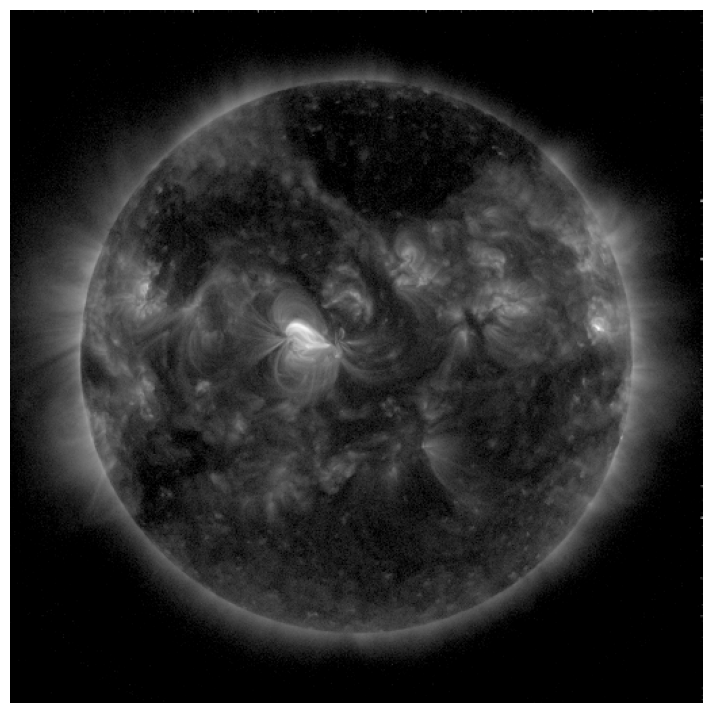

In [17]:
orig_img = Image.open(image_path).convert('L')

%matplotlib inline
plt.figure(figsize=(12, 9))
plt.axis('off')
plt.imshow(orig_img, cmap='gray')
plt.show()

#### Load checkpoint model with pretrained weights and Testing the original model Compression-Decompression

In [76]:
state_dict = torch.load(checkpoint_path, map_location=torch.device(device))['state_dict']
model = NASACompressor.from_state_dict(state_dict, strict=False).eval().to(device)
model.entropy_bottleneck.update()

x = transforms.ToTensor()(orig_img).unsqueeze(0).to(device)
print(x.shape)

with torch.no_grad():
    out = model.compress(x)
    
print("Compressed length: " + str(len(out['strings'][0][0])))
print("Compressed shape: " + str(out['shape']))
print('Output string:')
print(bytes(out['strings'][0][0]))

with torch.no_grad():
    rec_out = model.decompress(out['strings'], out['shape'])

torch.Size([1, 1, 512, 512])
Compressed length: 18832
Compressed shape: torch.Size([32, 32])
Output string:
b'\xa3~\x19g[\xde\t\x00\x0f\xba\xe9P7\xe5\xc5"l\t*\xbawC_\xe0\x1cQm\xdf\xe2\xdb\x14\xa8z\'B\xea\xd9=\xfd\x1d\xc3d\x12?\xd4{)\xb7V\xd4\x0c`\xc2:\xfeQ\x1a\xbd\xb3Yk \x1bt\xf0m\xc2\xae\x8ck\xda\x0fV\xf9hO\x9bb\x9b\x0c\xd3&o)3nG\xaf[\x18\x1c\xc4\xdd\xd4}\x9ev\x18`\x89%\x17\x13>5{tv\x01\x13\x1a\xb4`\xee:Y+[\xd9\xa7\x8dh\xbb\xefE\x8e^\x85\x95\x0eB\x9f\x15\x19\xa1}{\x19I\xc1S\x89q\ns\x891.\x98xo\xe6I\x85F\xd5\x89o\xc8\xe3B\\\x97\xf6\x8f\xf0\xdc\x08\xd4\x9c\x1cU\rwV\x9dK\xf9.^\x03\xc5"b\xa3\xe4\xd7\xe3\x1c\x9e\xbd\x9b\xa3\x14{\xa8q\xcf\x91\xc7.\xb9\xed\xc5\xa3@\xe7\xc7FLs\xe9$\x80|y\xe9\xc9%\x8b\xbc\xec\r\x1e\xe9\x9e\x07\xb8.\x1a:[\x88]e%\x8b~\xac\xa1\xcd\xc1\xceA\xde|qS[\xdd\x92&\x91\x1c|\xb7P\xe7\xde\xc3\xfbB.\x86\xd1\x1d\xe5$\x8ds4vA~y\x06\x8c<8y\xee\xf9\xa9#:\xfd\x19\x99Z8\x7f-\x1aD/\xff\xc8>pn\x08\x0f\xd8}\x06\xf81\x910\x84\xee\x16\xb0\x9c1?\x02W\x94\x8eQ3\xb6\xd2\xfe\x07t!\xb4U\xe8

#### Visualize the reconstruction

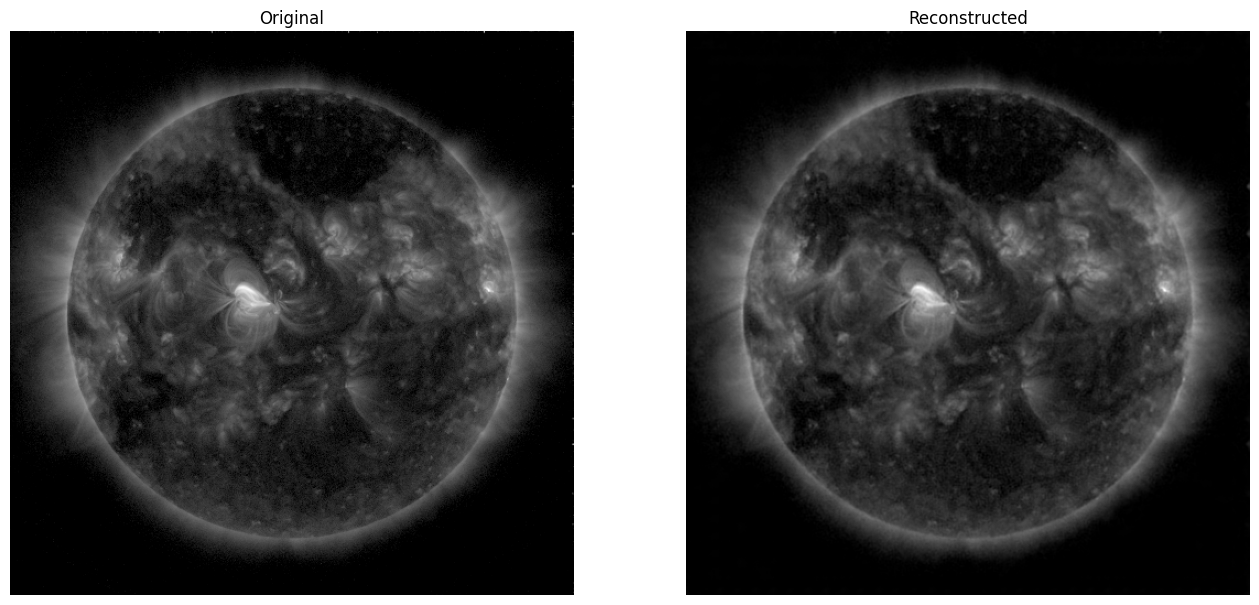

In [77]:
rec_image = transforms.ToPILImage()(rec_out['x_hat'].squeeze().cpu())

%matplotlib inline
fix, axes = plt.subplots(1, 2, figsize=(16, 12))
for ax in axes:
    ax.axis('off')
    
axes[0].imshow(orig_img, cmap='gray')
axes[0].title.set_text('Original')

axes[1].imshow(rec_image, cmap='gray')
axes[1].title.set_text('Reconstructed')

plt.show()

#### Load checkpoint model with pretrained weights and save it as a TorchScript

In [7]:
#torch.save(model, torchscript_path)
script_module = torch.jit.script(model)
print(type(script_module))
torch.jit.save(script_module, torchscript_path)

<class 'torch.jit._script.RecursiveScriptModule'>


## Testing the TorchScript model

#### Importing Libraries

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from torch.utils.data import Dataset
import os
from natsort import natsorted
import math
import numpy as np
from psutil import *
import time

torch.ops.load_library("./tiny_compressai/cpp_exts/ops/build/libtiny_compressai_cpp.so")
torch.classes.load_library("./tiny_compressai/cpp_exts/rans/build/libtiny_compressai_rans.so")

from tiny_compressai.models import NASACompressor

#### Defining paths and the preferred device to use

In [2]:
checkpoint_path = './model_checkpoint/sample_ckpt.ckpt'
torchscript_path = './torch_script/nasa_compressor.pt'
image_path = './grayscale_test/'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### Loading Torch Script model

In [3]:
#ts_model = torch.load(torchscript_path).to(device)
ts_model = torch.jit.load(torchscript_path).to(device)
ts_model.eval()

RecursiveScriptModule(
  original_name=NASACompressor
  (entropy_bottleneck): RecursiveScriptModule(
    original_name=EntropyBottleneck
    (likelihood_lower_bound): RecursiveScriptModule(original_name=LowerBound)
  )
  (g_a): RecursiveScriptModule(
    original_name=Sequential
    (0): RecursiveScriptModule(original_name=Conv2d)
    (1): RecursiveScriptModule(
      original_name=GDN
      (beta_reparam): RecursiveScriptModule(
        original_name=NonNegativeParametrizer
        (lower_bound): RecursiveScriptModule(original_name=LowerBound)
      )
      (gamma_reparam): RecursiveScriptModule(
        original_name=NonNegativeParametrizer
        (lower_bound): RecursiveScriptModule(original_name=LowerBound)
      )
    )
    (2): RecursiveScriptModule(original_name=Conv2d)
    (3): RecursiveScriptModule(
      original_name=GDN
      (beta_reparam): RecursiveScriptModule(
        original_name=NonNegativeParametrizer
        (lower_bound): RecursiveScriptModule(original_name=Lower

#### Create input images dataset

In [4]:
class CustomDataSet(Dataset):
    def __init__(self, main_dir, transform):
        self.main_dir = main_dir
        self.transform = transform
        all_imgs = os.listdir(main_dir)
        self.total_imgs = natsorted(all_imgs)

    def __len__(self):
        return len(self.total_imgs)

    def __getitem__(self, idx):
        img_loc = os.path.join(self.main_dir, self.total_imgs[idx])
        image = Image.open(img_loc).convert("L")
        tensor_image = self.transform(image)
        return tensor_image

batch_size = 4
num_workers = 0
transform = transforms.ToTensor()

dataset = CustomDataSet(image_path, transform)
test_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, num_workers=num_workers)
print(dataset)
print(len(dataset))

32


#### Plot images for visualization

torch.Size([4, 1, 512, 512])


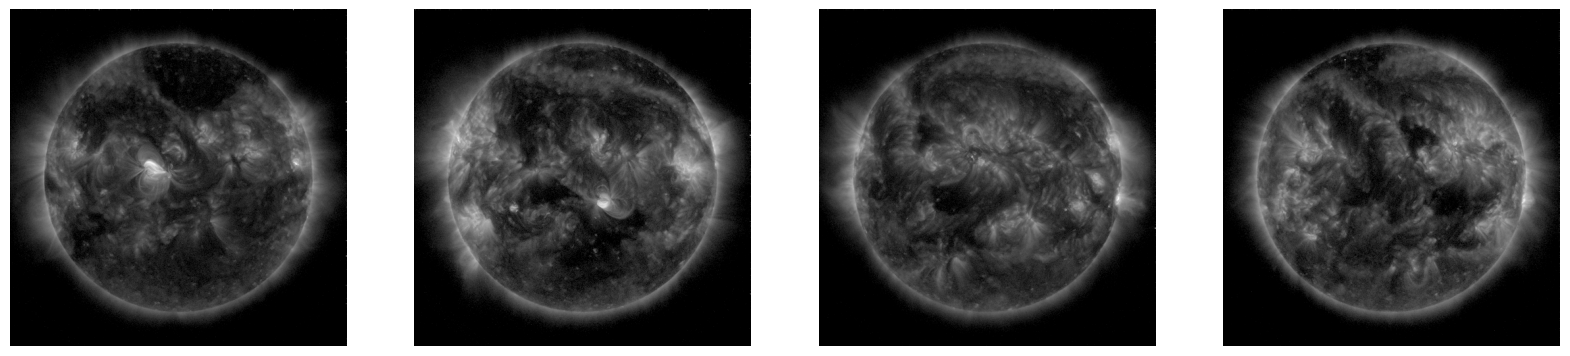

In [5]:
#plot only first batch
dataiter = iter(test_loader)
images = next(dataiter)

print(images.shape)

%matplotlib inline
fig, axes = plt.subplots(nrows=int(math.ceil(images.size(0)/4)), ncols=4, figsize=(20,10))

for image, ax in zip(images, axes.reshape(axes.size,1)):
    rec_image = transforms.ToPILImage()(image.squeeze().cpu())
    ax[0].imshow(rec_image, cmap='gray')
    ax[0].axis('off')

plt.show()


#### Testing Torch Script compression model to compare with cFS

In [6]:
elapsed = []
latency = 0.0
throughput = 0.0

with torch.no_grad():
  cpu_start = Process().cpu_percent()
  for images in test_loader:
      start = time.time()
      out = ts_model.compress(images)
      end = time.time()
      elapsed.append((end - start)/images.size(0))

      print('Output string:')
      print(len(out['strings'][0]))
    
  cpu_end = Process().cpu_percent()
    
latency = np.sum(elapsed)/len(test_loader)
lat_std = np.std(elapsed);
throughput = 1/latency;
cpu_usage = cpu_end - cpu_start
print('Latency: {:.6f}, Latency Std Dev: {:.6f}, Throughput: {:.2f}, CPU usage {:.6f}'.format(latency,lat_std,throughput,cpu_usage))


Output string:
4
Output string:
4
Output string:
4
Output string:
4
Output string:
4
Output string:
4
Output string:
4
Output string:
4
Latency: 1.520418, Latency Std Dev: 0.202328, Throughput: 0.66, CPU usage 0.000000


#### Load original model with pretrained weights and testing model Decompression only

In [7]:
state_dict = torch.load(checkpoint_path, map_location=torch.device(device))['state_dict']
model = NASACompressor.from_state_dict(state_dict, strict=False).eval().to(device)
model.entropy_bottleneck.update()

#Testing original model, but with compressed torch script model output
with torch.no_grad():
    rec_out = model.decompress(out['strings'], out['shape'])

#### Visualize the reconstruction

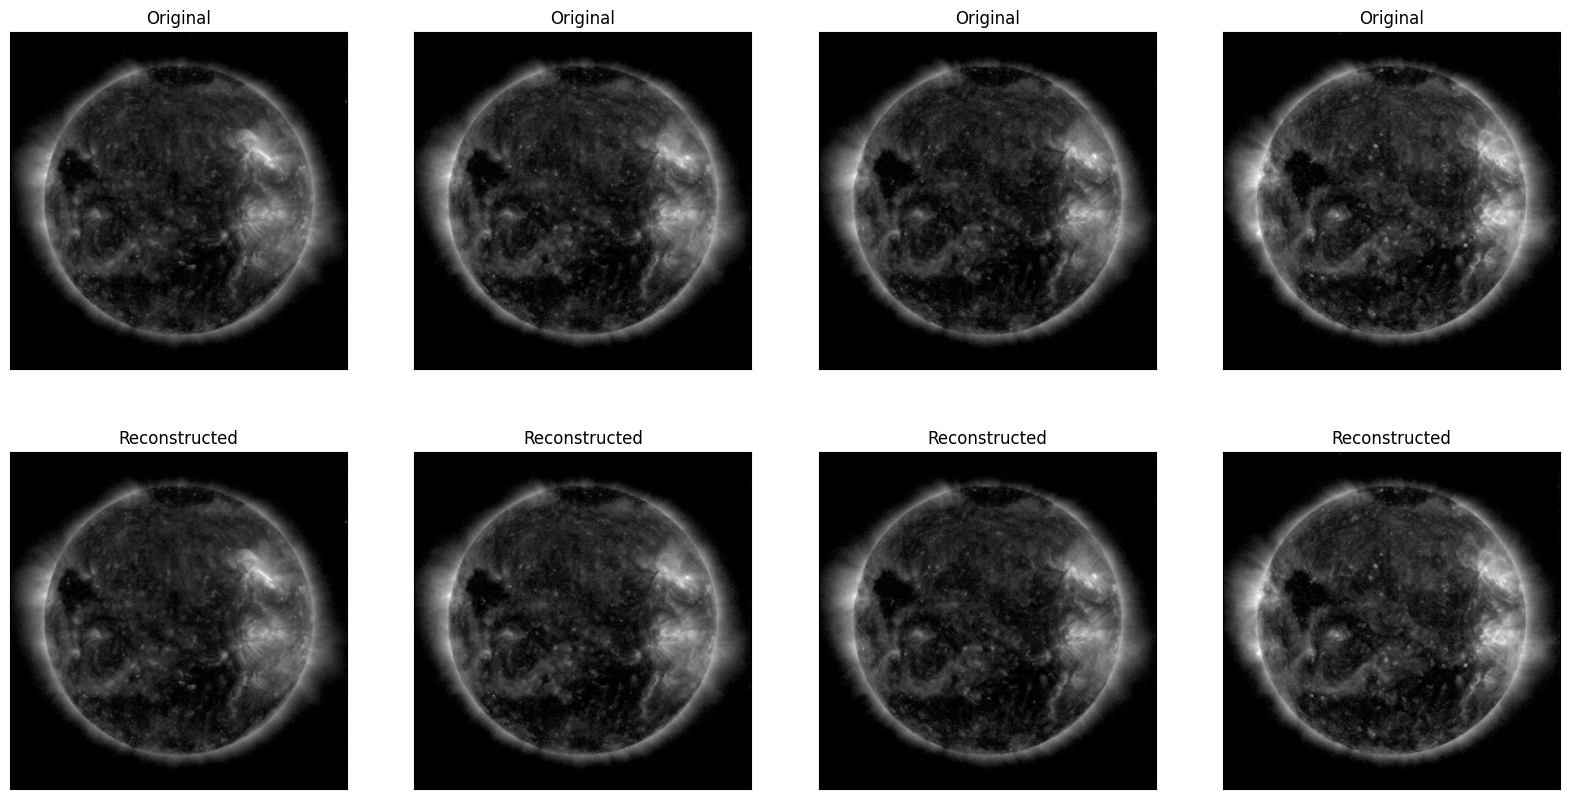

In [19]:
rec_images = rec_out['x_hat']

%matplotlib inline
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20,10))

# input images on top row, reconstructions on bottom
first_row = 1

for images, row in zip([images, rec_images], axes):
    for img, ax in zip(images, row):
        img = transforms.ToPILImage()(img.squeeze().cpu())
        ax.imshow(img, cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
        if first_row:
            ax.title.set_text('Original')    
        else:
            ax.title.set_text('Reconstructed')
    first_row = 0

plt.show()